# DR – Druhá semestrální práce

## Zadání

1. Získejte datovou sadu průměrných denních teplot v Plzni za období od 1. ledna 1970 do 12. prosince 2025.

2. Rozdělte datovou sadu podle jednotlivých kalendářních roků.

3. Vykreslete graf průměrných ročních teplot. V samostatném grafu zobrazte průběh denních teplot v jednotlivých letech.

4. Pomocí **nepárového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

5. Pomocí **párového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

6. Vykreslete histogram odchylek a posuďte, zda jsou splněny předpoklady pro použití t-testu.

7. Použijte vhodný **párový neparametrický** test a vyhodnoťte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

8. Porovnejte výsledky nepárového a párového t-testu. Vyhodnoťte, zda se statisticky významně odlišuje více, nebo méně roků při použití nepárového či párového testu. Stejně tak porovnejte výsledky párového t-testu a zvoleného párového neparametrického testu. Pokuste se vysvětlit případné rozdíly ve výsledcích.

9. Vyhodnoťte trend průměrných ročních teplot a otestujte hypotézu, že tento trend je statisticky významně odlišný od nuly.

## Dodatečné informace z emailu
Zadání opět vypacujte ve formě ipython notebooku a zašlete mi ho.

Jako úkol nad rámec zadání si můžete širokou paletu možnosti od srovnání s jinými místy planety až po analýzu, které dny v roce se více hodí pro porovnávání teplot. V zadání je také schválně ponechána jedna (a neúmyslně možná více) nepřesnost/nevhodnost. Její ohalení a náprava také může být úkolem nad rámec zadání.

Varování: pozor na příliš časté používání API zvolené služby. Nezapomínejte vyčkat několik sekund před opakováním dotazu.

## Vypracování

### 1. Získání datavé sady

Souřadnice Plzně jsou 49° 44′ 51″ N, 13° 22′ 39″ E (zdroj: https://en.wikipedia.org/wiki/Plze%C5%88).

Následuje definice parametrů datasetu:

In [95]:
# --------------------------------------------------
# Configuration
# --------------------------------------------------

location = {
    "name": "Pilsen",
    "continent": "Europe",
    "timezone": "Europe/Prague",
    "latitude": (49, 44, 51),
    "longitude": (13, 22, 39),
}

start_date = "1970-01-01"
# end_date = "2025-12-31"
end_date = "2025-12-12" # zadani rika 12. prosince, ale tady bylo napsano 31. prosince
# Preklep, nebo kontrola toho ze jsem cetl zadani?
# nebo kontrola toho ze to byla hozeny cely do LLMka?
# who knows

# --------------------------------------------------
# Derived parameters
# --------------------------------------------------

for key in ("latitude", "longitude"):
    degrees, minutes, seconds = location[key]
    location[key] = degrees + minutes / 60 + seconds / 3600

# --------------------------------------------------
# Output
# --------------------------------------------------

print(f"Location: {location['name']}")
print(f"Continent: {location['continent']}")
print(f"Timezone: {location['timezone']}")
print(f"Latitude: {location['latitude']:.3f}")
print(f"Longitude: {location['longitude']:.3f}")
print(f"Start date: {start_date}")
print(f"End date: {end_date}")

Location: Pilsen
Continent: Europe
Timezone: Europe/Prague
Latitude: 49.748
Longitude: 13.378
Start date: 1970-01-01
End date: 2025-12-12


Následuje výpočet, kolik bodů pozorování bychom měli dostat.

In [96]:
import datetime

date_start = datetime.date.fromisoformat(start_date)
date_end = datetime.date.fromisoformat(end_date)

n_days_expected = (date_end - date_start).days + 1

print(f"Start date: {date_start}")
print(f"End date: {date_end}")
print(f"Expected number of observations: {n_days_expected:,}")

Start date: 1970-01-01
End date: 2025-12-12
Expected number of observations: 20,435


K získání dat byla použita otavřená data s url adresou v následujícím kódu. Tento kód provádí záskání dat a kontrolu jejich správnosti.

In [ ]:
import requests
import pandas as pd
import json

# --------------------------------------------------
# Open-Meteo API
# --------------------------------------------------

url = "https://archive-api.open-meteo.com/v1/archive"

daily_variables = [
    "temperature_2m_mean",
    "temperature_2m_min",
    "temperature_2m_max",
]

params = {
    "latitude": location["latitude"],
    "longitude": location["longitude"],
    "start_date": start_date,
    "end_date": end_date,
    "daily": daily_variables,
    "timezone": location["timezone"],
    "models": "era5",
}

# --------------------------------------------------
# Download data
# --------------------------------------------------

# Pro prevenci příliš častého volání api jsem po prvním spuštění data uložil do souboru data.json
# with requests.Session() as session:
#     response = session.get(url, params=params, timeout=(10, 120))
#     response.raise_for_status()
#     result = response.json()

# json_str = json.dumps(result, indent=2)
# with open("data.json", "w") as f:
#     f.write(json_str)


with open("data.json") as f:
    result = json.load(f)



# --------------------------------------------------
# Extract data
# --------------------------------------------------

if "daily" not in result:
    raise ValueError("Daily data are missing from the API response.")

daily = result["daily"]

df = pd.DataFrame({
    "date": pd.to_datetime(daily["time"]),
    "temperature_mean": daily["temperature_2m_mean"],
    "temperature_min": daily["temperature_2m_min"],
    "temperature_max": daily["temperature_2m_max"],
})

# --------------------------------------------------
# Data validation
# --------------------------------------------------

print(f"Obtained observations: {len(df):,}")
print(f"Expected observations: {n_days_expected:,}")

if len(df) != n_days_expected:
    print("WARNING: Unexpected number of observations!")

if df["date"].duplicated().any():
    raise ValueError("Duplicate dates detected.")

if not df["date"].is_monotonic_increasing:
    raise ValueError("Dates are not in chronological order.")

missing = df.isna().sum()

if missing.any():
    print("\nMissing values:")
    print(missing[missing > 0])

# --------------------------------------------------
# API metadata
# --------------------------------------------------

print("\nTemperature units:")
print(result.get("daily_units", {}))

print(f"\nTimezone: {result.get('timezone')}")
print(f"Elevation: {result.get('elevation')} m")

df.head()

Obtained observations: 20,435
Expected observations: 20,435

Temperature units:
{'time': 'iso8601', 'temperature_2m_mean': '°C', 'temperature_2m_min': '°C', 'temperature_2m_max': '°C'}

Timezone: Europe/Prague
Elevation: 319.0 m


,date,temperature_mean,temperature_min,temperature_max
0,1970-01-01,-4.6,-5.6,-3.8
1,1970-01-02,-4.9,-6.3,-2.7
2,1970-01-03,-0.5,-2.7,1.1
3,1970-01-04,0.4,-2.3,1.9
4,1970-01-05,-2.0,-4.2,1.8


Následující kód vykreslí všechny body datové sady.

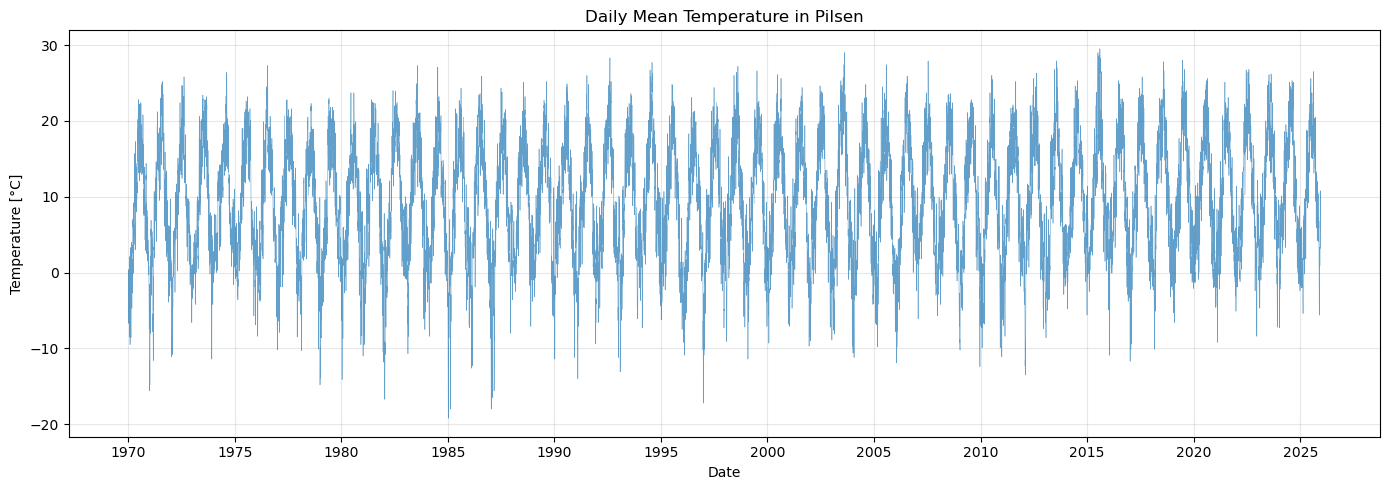

In [98]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# Plot daily temperature
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df["date"],
    df["temperature_mean"],
    linewidth=0.4,
    alpha=0.7,
)

ax.set_title(f"Daily Mean Temperature in {location['name']}")
ax.set_ylabel("Temperature [°C]")
ax.set_xlabel("Date")

# Date formatting
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

### 2. Rozdělení datové sady

In [99]:
# --------------------------------------------------
# Split data into annual DataFrames
# --------------------------------------------------

df["year"] = df["date"].dt.year

df_annual = {
    year: group.drop(columns="year").reset_index(drop=True)
    for year, group in df.groupby("year")
}

print(f"Number of years: {len(df_annual)}")
print(f"Available years: {list(df_annual.keys())}")

df_annual[2025]

Number of years: 56
Available years: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,date,temperature_mean,temperature_min,temperature_max
0,2025-01-01,2.6,-0.8,6.1
1,2025-01-02,4.4,0.0,8.0
2,2025-01-03,0.5,-0.4,1.9
3,2025-01-04,-0.8,-3.7,0.5
4,2025-01-05,-0.0,-4.3,5.5
...,...,...,...,...
341,2025-12-08,10.2,6.9,12.5
342,2025-12-09,10.8,8.8,12.8
343,2025-12-10,8.1,6.2,10.1
344,2025-12-11,7.5,3.0,10.2


### 3. Vykreslení průběhů teplot

Následují kód vykresluje vývoj průměrné roční teploty.

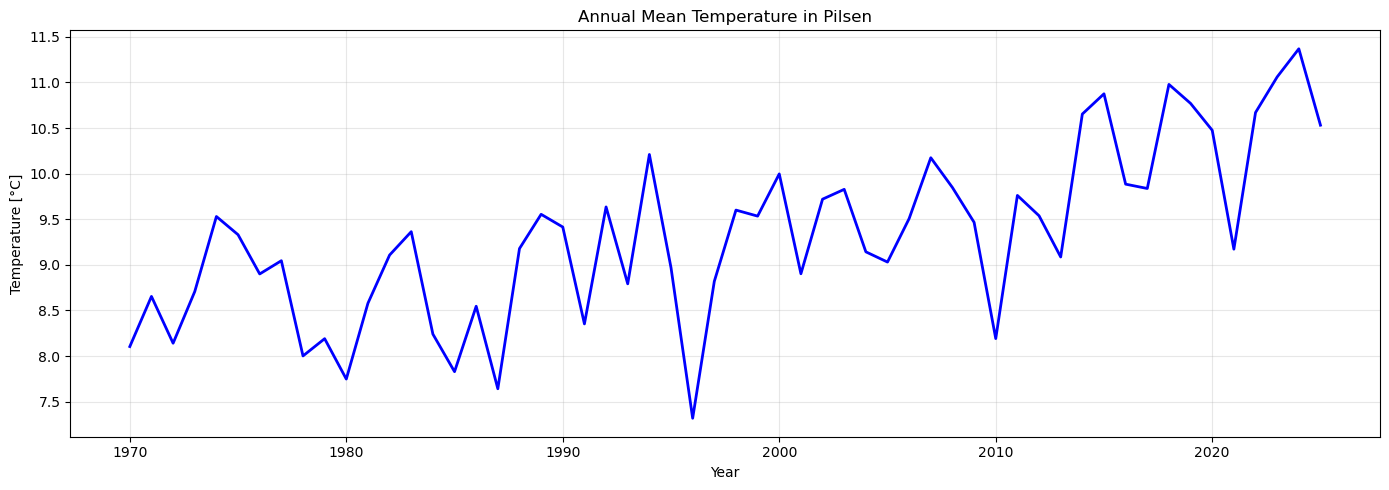

In [100]:
# --------------------------------------------------
# Annual temperature statistics
# --------------------------------------------------

df_annual_stats = pd.DataFrame({
    year: {
        "mean": data["temperature_mean"].mean(),
    }
    for year, data in df_annual.items()
}).T
df_annual_stats.index.name = "year"

# --------------------------------------------------
# Plot annual mean temperature ± standard deviation
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))
years = df_annual_stats.index
means = df_annual_stats["mean"]
ax.plot(years, means, color="blue", linewidth=2.0)
ax.set_title(f"Annual Mean Temperature in {location['name']}")
ax.set_xlabel("Year")
ax.set_ylabel("Temperature [°C]")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Následující kód vykresluje průběh teplot během roku a průměrný rok.

C:\Users\samko\AppData\Local\Temp\ipykernel_54600\3678153298.py:23: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["date"].dt.dayofyear,
C:\Users\samko\AppData\Local\Temp\ipykernel_54600\3678153298.py:23: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["date"].dt.dayofyear,
C:\Users\samko\AppData\Local\Temp\ipykernel_54600\3678153298.py:23: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["date"].dt.dayofyear,
C:\Users\samko\AppData\Local\Temp\ipykernel_54600\3678153298.py:23: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["date"].dt.dayofyear,
C:\Users\samko\AppData\Local\Temp\ipykernel_54600\3678153298.py:23: Pandas4Warning: Series.dt.dayofyear is d

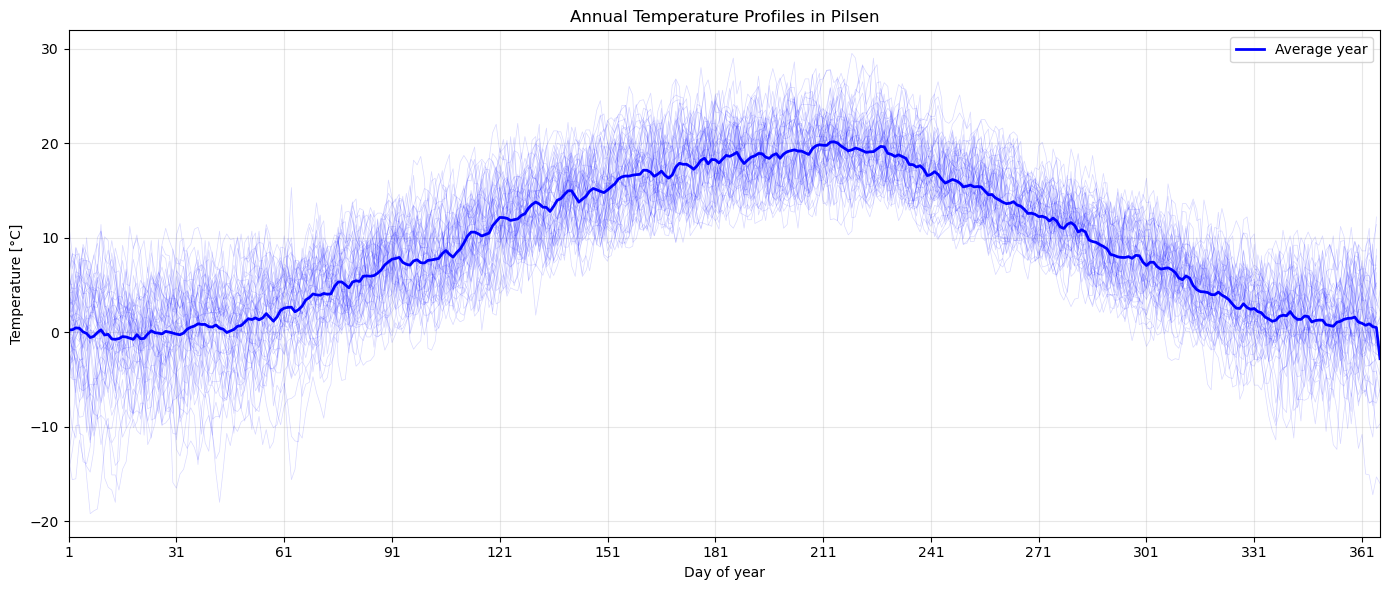

In [101]:
# --------------------------------------------------
# Average annual temperature profile
# --------------------------------------------------

df["day_of_year"] = df["date"].dt.day_of_year # dayofyear je depracated

df_average_year = (
    df.groupby("day_of_year")["temperature_mean"]
    .agg(["mean", "std"])
    .reset_index()
)

df_average_year.head()

# --------------------------------------------------
# Plot temperature profiles for all years
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for year, data in df_annual.items():
    ax.plot(
        data["date"].dt.dayofyear,
        data["temperature_mean"],
        color="blue",
        linewidth=0.5,
        alpha=0.15,
    )

# Average annual profile
ax.plot(
    df_average_year["day_of_year"],
    df_average_year["mean"],
    linewidth=2.0,
    color="blue",
    label="Average year",
)

ax.set_title(f"Annual Temperature Profiles in {location['name']}")
ax.set_xlabel("Day of year")
ax.set_ylabel("Temperature [°C]")

ax.set_xlim(1, 366)
ax.set_xticks(range(1, 367, 30))

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

# Zadání (abych nemusel scrollovat nahoru a dolů)
4. Pomocí **nepárového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

5. Pomocí **párového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

6. Vykreslete histogram odchylek a posuďte, zda jsou splněny předpoklady pro použití t-testu.

7. Použijte vhodný **párový neparametrický** test a vyhodnoťte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

8. Porovnejte výsledky nepárového a párového t-testu. Vyhodnoťte, zda se statisticky významně odlišuje více, nebo méně roků při použití nepárového či párového testu. Stejně tak porovnejte výsledky párového t-testu a zvoleného párového neparametrického testu. Pokuste se vysvětlit případné rozdíly ve výsledcích.

9. Vyhodnoťte trend průměrných ročních teplot a otestujte hypotézu, že tento trend je statisticky významně odlišný od nuly.

### 4. Použití nepárových testů

Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití nepárového t-testu:

\begin{align}
H_0:& \mu_\text{rok} = \mu_\text{avg},\\
H_1 (\text{rok je jiný}):& \mu_\text{rok} \ne \mu_\text{avg},\\
H_1 (\text{rok je chladnější}):& \mu_\text{rok} < \mu_\text{avg},,\\
H_1(\text{rok je teplejší}):& \mu_\text{rok} > \mu_\text{avg},\\
\end{align}

In [102]:
tests_results = {}

In [103]:
from scipy.stats import ttest_ind

test_name = "t-test"
test_type = "independent"

tests_results[test_name] = {
        test_type: {
            "two-sided": {},
            "less": {},
            "greater": {},
        },
}

average_year = df_average_year["mean"]

# df_annual obsahuje data temp_mean, temp_min, temp_max a dny a je to groupnute podle roku
for year, data in df_annual.items():

    actual_year = data["temperature_mean"] # vsechny data v roce

    p_value_two_sided = ttest_ind(actual_year,
                                   average_year,
                                   equal_var=False,
                                   alternative="two-sided").pvalue
    p_value_less = ttest_ind(actual_year,
                             average_year,
                             equal_var=False,
                             alternative="less").pvalue
    p_value_greater = ttest_ind(actual_year,
                                 average_year,
                                 equal_var=False,
                                 alternative="greater").pvalue  

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [9]: [1980, 1987, 1996, 2014, 2015, 2018, 2019, 2023, 2024]
Významně chladnější roky (less)   [5]: [1978, 1980, 1985, 1987, 1996]
Významně teplejší roky (greater)  [8]: [2014, 2015, 2018, 2019, 2022, 2023, 2024, 2025]


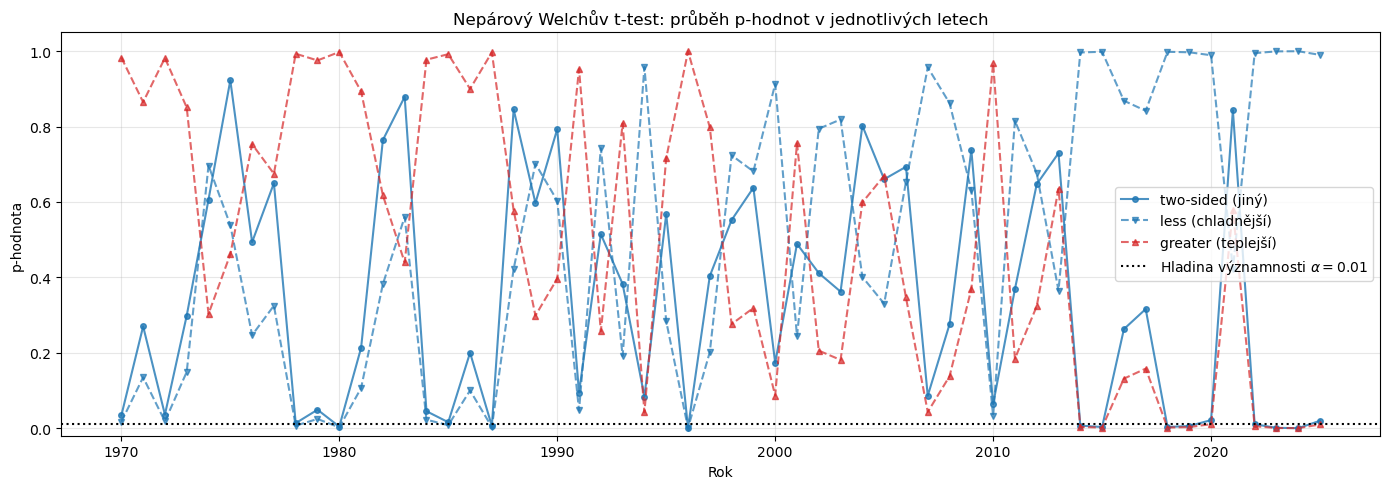

In [104]:
def plot_test_results(results, alpha=0.01, title="Grafické zobrazení p-hodnot"):

    years_list = list(results["two-sided"].keys())
    p_two = list(results["two-sided"].values())
    p_less = list(results["less"].values())
    p_greater = list(results["greater"].values())

    # Výpis statisticky významných let na hladině alpha = 0.01
    sig_different = [y for y, p in results["two-sided"].items() if p < alpha]
    sig_colder = [y for y, p in results["less"].items() if p < alpha]
    sig_warmer = [y for y, p in results["greater"].items() if p < alpha]

    print(f"Hladina významnosti alpha = {alpha}")
    print(f"Významně odlišné roky (two-sided) [{len(sig_different)}]: {sig_different}")
    print(f"Významně chladnější roky (less)   [{len(sig_colder)}]: {sig_colder}")
    print(f"Významně teplejší roky (greater)  [{len(sig_warmer)}]: {sig_warmer}")

    # Vykreslení průběhu p-hodnot
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.set_title(title);
    ax.plot(years_list, p_two, marker="o", markersize=4, linestyle="-", alpha=0.8, label="two-sided (jiný)")
    ax.plot(years_list, p_less, marker="v", markersize=4, linestyle="--", alpha=0.7, color="tab:blue", label="less (chladnější)")
    ax.plot(years_list, p_greater, marker="^", markersize=4, linestyle="--", alpha=0.7, color="tab:red", label="greater (teplejší)")

    ax.axhline(y=alpha, color="black", linestyle=":", linewidth=1.5, label=f"Hladina významnosti $\\alpha = {alpha}$")

    ax.set_xlabel("Rok")
    ax.set_ylabel("p-hodnota")
    ax.set_ylim(-0.02, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()


    # ax.set_title("")
results = tests_results["t-test"]["independent"]
plot_test_results(results, title="Nepárový Welchův t-test: průběh p-hodnot v jednotlivých letech")

In [105]:
print(tests_results["t-test"]["independent"]["two-sided"][2022])

print(tests_results["t-test"]["independent"]["greater"][2022])

0.010356499505154458
0.005178249752577229


- pozn. pro Sama
## Hladina významnosti 
- hladina významnosti je předem nastavená chyba prvního druhu (skutečnost, že platí $H_0$, ale mi ji omylem zamítneme)
- je to konstanta
## P-hodnota    
- p-hodnota je ppst kterou spočítáš z dat 
- v našem případě teplot:
    - je to ppst, že v v normálním roce vznikne náhodou alespoň tak velká odchylka od průměru, kterou jsme naměřili

- malá p-hodnota:
    - kdyby daný rok měl p-hodnotu třeba $p=0.0002=0.02%$, tak kdyby ten rok byl opravdu průměrný, tak takový výsledek padne náhodou jen jednou za 5000 let $\to$ to už není náhoda $\to$ $H_0$ nevěříme a zamítáme ji


- pravidlo porovnání těchto dvou hodnot:
"If the p is low, the null must go" 
- kdyz je p-hodnota nízká, většinou zamítáme nulovou hypotézu

Zajímavá skutečnost: 
- pro roky zamítáme $H_0$ 2022, 2023 i 2024 ve prospěch $H_1(\text{rok je teplejší}): \mu_\text{rok} > \mu_\text{avg}$
- pro roky 2023, 2024 zamítáme $H_0$ ve prospěch $H_1 (\text{rok je jiný}): \mu_\text{rok} \ne \mu_\text{avg}$, ale to se nestane pro rok 2022
- proč se tomu tak děje?
- oboustranný test dělí hladinu významnosti na dvě poloviny 
- p-hodnota u oboustraného testu je poté dvojnásobkem p-hodnoty jednostranného testu 
- u roku 2022 vyšla jednostranná p-hodnota mezi $0.005$ a $0.01$, což stačí na zamítnutí $H_0$, ale po vynásobení dvěma přeskočila hrancii $\alpha$ pro oboustranný test


### 5. Použití párových testů

Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití nepárového t-testu:

\begin{align}
H_0:& \mu_\text{rok} = \mu_\text{avg},\\
H_1 (\text{rok je jiný}):& \mu_\text{rok} \ne \mu_\text{avg},\\
H_1 (\text{rok je chladnější}):& \mu_\text{rok} < \mu_\text{avg},,\\
H_1(\text{rok je teplejší}):& \mu_\text{rok} > \mu_\text{avg},\\
\end{align}

In [106]:
from scipy.stats import ttest_rel

test_name = "t-test"
test_type = "paired"

# Tady byla chybka pri prepisovani puvodnich dat
tests_results[test_name][test_type] = {
            "two-sided": {},
            "less": {},
            "greater": {},
}




average_year_with_days = df_average_year[["mean","day_of_year"]]
print(len(average_year_with_days))
# prumerny rok obsahuje data i z 29. unora, coz je pouze pro prestupni roky

for year, data in df_annual.items():
    # Musim mergenout podle datumu!
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"]
    })

    # data nejdrive mergnu, abych zajistil ze se v kazdem roce porovnavaji spravne dny
    merged = pd.merge(
        actual_year_df,
        average_year_with_days,
        on="day_of_year",
        how="left",
    )

    actual_year_data = merged["temperature"]
    average_year_data = merged["mean"]


    p_value_two_sided = ttest_rel(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less = ttest_rel(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater = ttest_rel(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

366


Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [30]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2007, 2008, 2010, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [18]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1993, 1996, 1997, 2001, 2010]
Významně teplejší roky (greater)  [17]: [1994, 2000, 2003, 2007, 2008, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


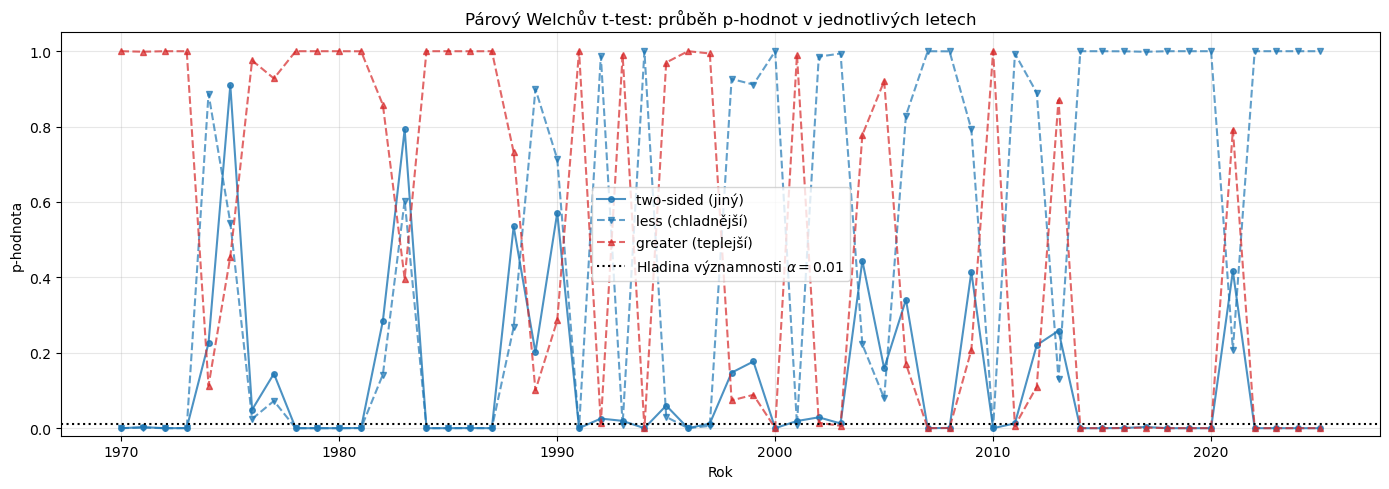

In [107]:
results = tests_results["t-test"]["paired"]
plot_test_results(results, title="Párový Welchův t-test: průběh p-hodnot v jednotlivých letech")

### Párový ttest je statisticky "silnější", protože rozptyl dat,se kterými počítáme, je mnohem menší

### 6. Analýza histogramu odchylek

Následující kód vykreslí histogram odchylek a zakreslí průběh normálního rozdělení se střední hodnotou a rozptylem odpovídající střední hodnotě a rozptylu odchylek.

In [108]:
# Predpoklady ttestu
    # histogram odchylek by mel odpovida normalnimu rozdeleni
    # nezavislost pozorovani

df

,date,temperature_mean,temperature_min,temperature_max,year,day_of_year
0,1970-01-01,-4.6,-5.6,-3.8,1970,1
1,1970-01-02,-4.9,-6.3,-2.7,1970,2
2,1970-01-03,-0.5,-2.7,1.1,1970,3
3,1970-01-04,0.4,-2.3,1.9,1970,4
4,1970-01-05,-2.0,-4.2,1.8,1970,5
...,...,...,...,...,...,...
20430,2025-12-08,10.2,6.9,12.5,2025,342
20431,2025-12-09,10.8,8.8,12.8,2025,343
20432,2025-12-10,8.1,6.2,10.1,2025,344
20433,2025-12-11,7.5,3.0,10.2,2025,345


In [109]:
df_average_year

,day_of_year,mean,std
0,1,0.253571,5.182136
1,2,0.250000,4.847305
2,3,0.460714,5.144765
3,4,0.416071,5.116241
4,5,0.039286,5.418141
...,...,...,...
361,362,0.732727,4.452426
362,363,0.883636,4.967329
363,364,0.592727,5.105257
364,365,0.494545,5.042355


In [110]:
merged_df_for_deviation = pd.merge(
    df,
    df_average_year,
    on="day_of_year",
    how="left"
   )
merged_df_for_deviation
# Pozor! std asi neni to co chci?

,date,temperature_mean,temperature_min,temperature_max,year,day_of_year,mean,std
0,1970-01-01,-4.6,-5.6,-3.8,1970,1,0.253571,5.182136
1,1970-01-02,-4.9,-6.3,-2.7,1970,2,0.250000,4.847305
2,1970-01-03,-0.5,-2.7,1.1,1970,3,0.460714,5.144765
3,1970-01-04,0.4,-2.3,1.9,1970,4,0.416071,5.116241
4,1970-01-05,-2.0,-4.2,1.8,1970,5,0.039286,5.418141
...,...,...,...,...,...,...,...,...
20430,2025-12-08,10.2,6.9,12.5,2025,342,1.653571,4.416291
20431,2025-12-09,10.8,8.8,12.8,2025,343,1.358929,4.379239
20432,2025-12-10,8.1,6.2,10.1,2025,344,1.355357,4.068992
20433,2025-12-11,7.5,3.0,10.2,2025,345,1.708929,3.644985


In [111]:
deviation = merged_df_for_deviation["temperature_mean"] - merged_df_for_deviation["mean"]
print(deviation)
# odchylky uz mas => staci vykreslit histogram => todo histogram

0       -4.853571
1       -5.150000
2       -0.960714
3       -0.016071
4       -2.039286
           ...   
20430    8.546429
20431    9.441071
20432    6.744643
20433    5.791071
20434    1.550000
Length: 20435, dtype: float64


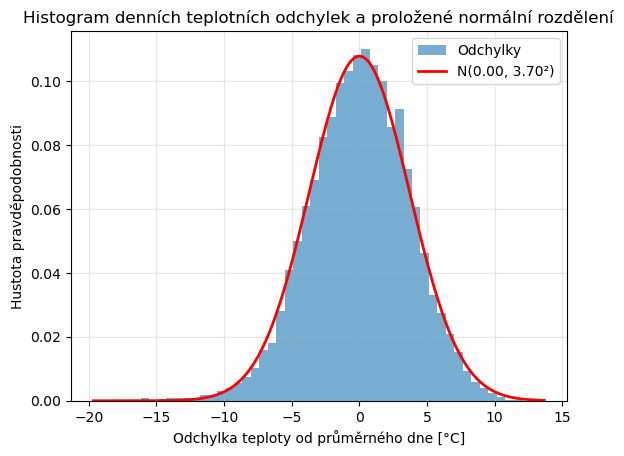

In [112]:
import numpy as np
from scipy.stats import norm

mean_dev = np.mean(deviation)
std_dev = np.std(deviation)
x = np.linspace(deviation.min()-1, deviation.max()+1, 200)
pdf = norm.pdf(x, mean_dev, std_dev)    

plt.figure()
plt.hist(deviation, bins=50, density=True, alpha=0.6, label="Odchylky")
plt.plot(x, pdf, "r-", lw=2, label=f"N({mean_dev:.2f}, {std_dev:.2f}²)")
plt.title("Histogram denních teplotních odchylek a proložené normální rozdělení")
plt.xlabel("Odchylka teploty od průměrného dne [°C]")
plt.ylabel("Hustota pravděpodobnosti")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



Porovnáním histogramu odchylek a odpovídajícího normálního rozdělení vidíme, že tvar Gaussovy křivky věrně kopíruje rozdělení odchylek. Je vidět mírné levostranné zašikmení.

K T-testu je ještě nutné podotknout, že předpokládá nezávislost jednotlivých pozorování. To u denních teplot ovšem není zaručeno. Teploty po sobě jdoucích dnech jsou korelované.

Přestože histogram odchylek odpovídá normálnímu rozdělení (a tím se splňuje jeden předpoklad T-testu), druhý předpoklad není zcela splněn, což může vést k nadhodnocení statistické významnosti. (Tz. test je moc sebevědomý, příliš snadno a často zamítá $H_0$ i když by neměl).

### 7. Použití neparametrického párového testu

**Wilconxonův test:**
- ptá se: "Jsou kladné a záporné odchylky rozložené symetricky kolem nuly?" 
- tj. je medián rozdílů == 0?

- předepsané buňky mluví o průměru, LLM mi řeklo, že se počítá s mediánem (resp. s rozdělením odchylek kolem nuly)?


Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití vybraného neparametrického testu:

\begin{align}
H_0:&\ \text{median}(d)=0,\\
H_1 (\text{rok je jiný}):& \text{median}(d)\ne 0,\\
H_1 (\text{rok je chladnější}):&\text{median}(d)<0 ,\\
H_1(\text{rok je teplejší}):&\text{median}(d)>0 ,\\
\end{align}

In [113]:
from scipy.stats import wilcoxon

test_name = "wilcoxon"
test_type = "paired"

tests_results[test_name] = {
    test_type: {
        "two-sided": {},
        "less": {},
        "greater": {}
        }
}


average_year_with_days = df_average_year[["mean","day_of_year"]]
print(len(average_year_with_days))
# prumerny rok obsahuje data i z 29. unora, coz je pouze pro prestupni roky

for year, data in df_annual.items():
    # Musim mergenout podle datumu!
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"]
    })

    # data nejdrive mergnu, abych zajistil ze se v kazdem roce porovnavaji spravne dny
    merged = pd.merge(
        actual_year_df,
        average_year_with_days,
        on="day_of_year",
        how="left",
    )

    actual_year_data = merged["temperature"]
    average_year_data = merged["mean"]


    p_value_two_sided = wilcoxon(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less = wilcoxon(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater = wilcoxon(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

366


Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [31]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2003, 2007, 2008, 2010, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [15]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1996, 1997, 2010]
Významně teplejší roky (greater)  [18]: [1994, 2000, 2003, 2007, 2008, 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


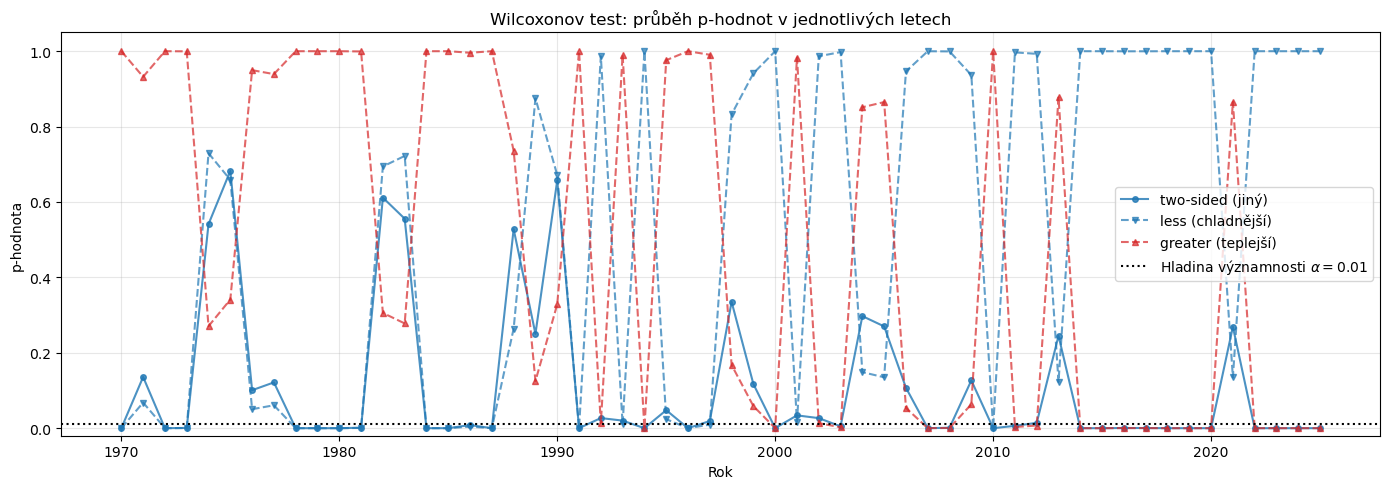

In [114]:
plot_test_results(tests_results[test_name][test_type], title=f"Wilcoxonov test: průběh p-hodnot v jednotlivých letech")

### 8. Analýza rozdílů použitých testů

In [115]:
def get_sig_years(test_name, test_type, alternative, alpha=0.01):
    p_vals = tests_results[test_name][test_type][alternative]
    return {year for year, p in p_vals.items() if p < alpha}

def comparison_table(alpha = 0.01):
    alternatives = {
        "two-sided": "Jiný (two-sided)",
        "less": "Chladnější (less)",
        "greater": "Teplejší (greater)",
    }
    rows = []
    for alt_key, alt_label in alternatives.items():
        ind_t = get_sig_years("t-test", "independent", alt_key, alpha)
        rel_t = get_sig_years("t-test", "paired", alt_key, alpha)
        wilc = get_sig_years("wilcoxon", "paired", alt_key, alpha)

        rows.append({
            "Hypotéza": alt_label,
            "Nepárový t-test (počet)": len(ind_t),
            "Párový t-test (počet)": len(rel_t),
            "Pouze párový t-test oproti nepárovému [počet]": len(rel_t - ind_t),
            "|" : "|",
            "Wilcoxon párový (počet)": len(wilc),
            "Párový t-test oproti Wilcoxon [roky[": sorted(rel_t - wilc),
            "Wilcoxon oprorti Párový t-test [roky]": sorted(wilc - rel_t),
        })
    return rows

df_comparison = pd.DataFrame(comparison_table())
display(df_comparison)

,Hypotéza,Nepárový t-test (počet),Párový t-test (počet),Pouze párový t-test oproti nepárovému [počet],|,Wilcoxon párový (počet),Párový t-test oproti Wilcoxon [roky[,Wilcoxon oprorti Párový t-test [roky]
0,Jiný (two-sided),9,30,21,|,31,[1971],"[2003, 2011]"
1,Chladnější (less),5,18,13,|,15,"[1971, 1993, 2001]",[]
2,Teplejší (greater),8,17,9,|,18,[],[2012]


...

Z analýzy vychází, že méně roků prochází nepárovým testem než párovým testem pro hladinu významnosti $\alpha = 0.01$.

Důvodem je robustnost párového testu vůči odchylkám. V nepárovém testu jsou odchylky hodnot napříč rokem obrovské. U párového testu nás zajímají odchylky pouze odpovídajících dnů a jsou tedy menší a "snadněji" se překonají.

Z analýzy vychází, že přibližně stejný počet roků prochází jak t-testem, tak neparametrickým testem pro hladinu významnosti $\alpha = 0.01$.

V tabulce výše jsou vidět konkrétní roky, ve kterých se paramterické testy liší oproti neparamterickému.

V teplotách se vyskytují extrémní mrazy (z histogramu odchylek jsou vidět odchylky až $-16^\circ\text{C}$), které nemají na kladné straně protějšek. T-test počítá s aritmetickým průměrem odchylek a tyto výrazné záporné odchylky strhly průměr směrem dolů.

Wilcoxonův test pracuje s pořadím. Výrazně mrazivý den nemá statisticky výraznější hodnotu než "obyčejný" chladný den.

Kvůli zápornému zešikmení leží medián (se kterým počítáme u neparamterického testu) o něco výše než jejich průměr.

T-test, který pracuje s průměrem tedy zachytil trochu více chladnějších let (o tři), zatímco Wilcoxonův neparametrický test zachytil více teplejších let (o jeden). 

Níže je tabulka srovnávající testy na hladině významnosti $\alpha=0.05$, jsou rozdíly mezi testy velice podobné jako pro hladinu významnosti $\alpha=0.01$.

In [116]:
df_comparison = pd.DataFrame(comparison_table(alpha=0.05))
display(df_comparison)

,Hypotéza,Nepárový t-test (počet),Párový t-test (počet),Pouze párový t-test oproti nepárovému [počet],|,Wilcoxon párový (počet),Párový t-test oproti Wilcoxon [roky[,Wilcoxon oprorti Párový t-test [roky]
0,Jiný (two-sided),18,38,20,|,38,"[1971, 1976]","[1995, 2012]"
1,Chladnější (less),11,20,9,|,18,"[1971, 1976]",[]
2,Teplejší (greater),11,19,8,|,20,[],[2012]


### 9. Analýza trendu

Obecná formulace hypotézy o trendu (slop):

* H0: trend je nulový
* H1: trend je nenulový.


Nalezení trendu, vykreslení a vyhodnocení p-hodnoty.

In [117]:
...

Ellipsis

Z výsledků vyplývá ...

## Vypracování úkolu/ů nad rámec zadání

...

## Závěr

...